# Bivariate Analysis - Healthcare Dataset
Weekly graph question, project dataset analysis, and Storytelling With Data plot.

**Before running:** put `insurance.csv` in the same folder as this notebook. It is the Kaggle dataset
[Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Weekly graph question
Suppose you wanted to show the nitrate and phosphate level in a water sample. What are the advantages and disadvantages of showing this as an area plot, as opposed to two separate line graphs? How would you adjust the graphs shown to improve the presentation?

Text(0, 0.5, 'Nitrate level (% of eutrophic value)')

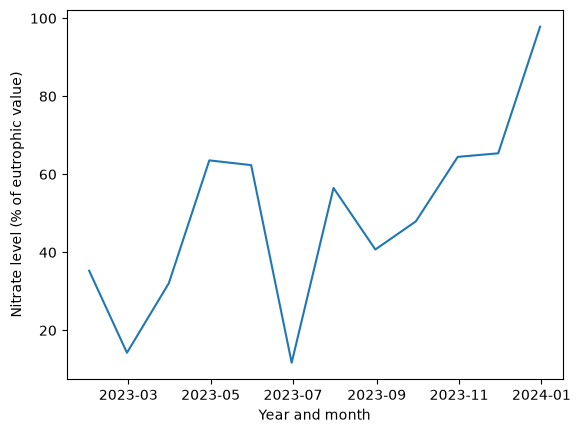

In [2]:
numdates = 12
np.random.seed(0)
time_series = 100 * (np.random.normal(size = numdates) / 5 + np.arange(numdates) / 16)
# 'ME' = month end (pandas 2.2+ replaced the old 'M' alias)
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='ME')
ax = sns.lineplot(x = datearray, y = time_series)
ax.set_xlabel("Year and month")
ax.set_ylabel("Nitrate level (% of eutrophic value)")

Text(0, 0.5, 'Phosphate level (% of eutrophic value)')

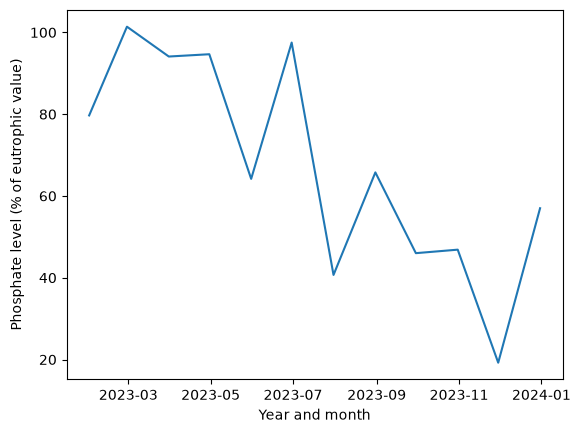

In [3]:
np.random.seed(1)
time_series_2 =  100 * (1 - (np.random.normal(size = numdates) / 8 + np.arange(numdates) / 16))
ax = sns.lineplot(x = datearray, y = time_series_2)
ax.set_xlabel("Year and month")
ax.set_ylabel("Phosphate level (% of eutrophic value)")

<Axes: >

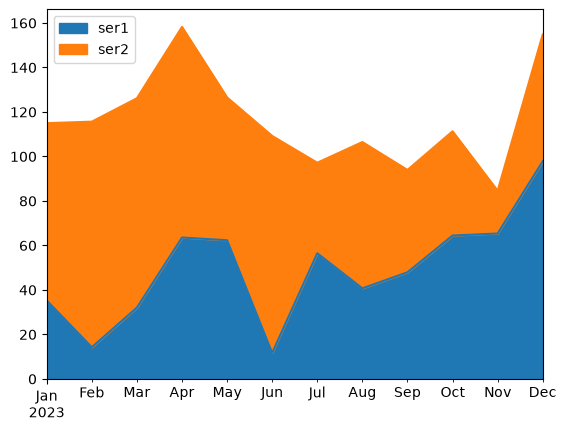

In [4]:
df = pd.DataFrame({'ser1': time_series, 'ser2': time_series_2}, index = datearray)
df.plot.area()

### Answer

**Advantages of the area plot**
- Both chemicals appear on one chart, with one time axis, so it's easy to see that nitrate rises while phosphate falls.
- The top edge shows the combined total, which is useful *if* the total means something.
- It takes up less space than two charts.

**Disadvantages of the area plot**
- `df.plot.area()` **stacks** the series by default. Only the bottom series (nitrate) can be read against the y-axis; the phosphate band's height has to be estimated as the gap between two wavy lines, which is hard to judge.
- The total is not meaningful here. Adding "% of eutrophic value" for nitrate to "% of eutrophic value" for phosphate gives a number with no physical interpretation, yet the area plot emphasises it most.
- Stacking hides phosphate's decline: nitrate rises about as fast as phosphate falls, so the top edge of the phosphate band stays roughly flat all year, and a reader could easily conclude phosphate isn't changing.
- The reader can't compare either chemical to the 100% eutrophic threshold, which is the main thing they care about.

**Advantages of two separate line graphs**
- Each chemical is read directly against its own axis.
- But: the two graphs have different y-axis ranges, so they look similar in size even when they aren't, and the reader has to look back and forth to compare months.

**Improvements**
1. Put both chemicals on **one line chart with a shared y-axis** (they use the same unit, % of eutrophic value), not stacked.
2. Draw a **reference line at 100%** labelled "Eutrophic threshold", since that's what makes the numbers meaningful.
3. **Label the lines directly** with "Nitrate" and "Phosphate" instead of `ser1`/`ser2` and a legend.
4. Give the chart a **title that states the takeaway**, label the axes and use readable month ticks.
5. If an area plot is used at all, use `stacked=False` with transparency so each band starts at zero.

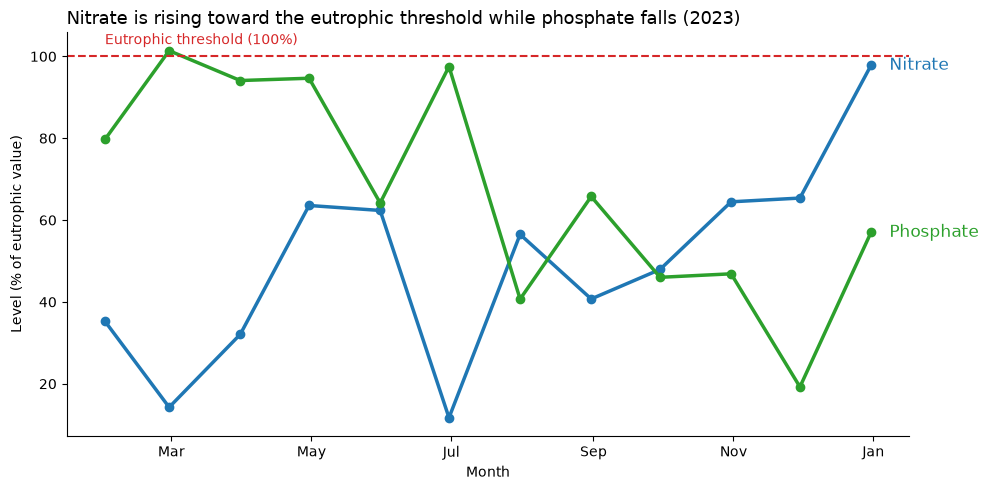

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(datearray, time_series,   color='#1f77b4', linewidth=2.5, marker='o')
ax.plot(datearray, time_series_2, color='#2ca02c', linewidth=2.5, marker='o')
ax.axhline(100, color='#d62728', linestyle='--', linewidth=1.5)

ax.text(datearray[-1] + pd.Timedelta(days=8), time_series[-1],   'Nitrate',   color='#1f77b4', va='center', fontsize=12)
ax.text(datearray[-1] + pd.Timedelta(days=8), time_series_2[-1], 'Phosphate', color='#2ca02c', va='center', fontsize=12)
ax.text(datearray[0], 103, 'Eutrophic threshold (100%)', color='#d62728', fontsize=10)

for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.set_title('Nitrate is rising toward the eutrophic threshold while phosphate falls (2023)',
             loc='left', fontsize=13)
ax.set_ylabel('Level (% of eutrophic value)')
ax.set_xlabel('Month')
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b'))
plt.tight_layout()
plt.show()

# 3. Project dataset: Medical Cost Personal Datasets (Kaggle)
Each of the 1,338 rows is one person with US health insurance:

| Column | Meaning |
|---|---|
| `age` | Age of the primary beneficiary (18-64) |
| `sex` | female / male |
| `bmi` | Body mass index |
| `children` | Number of dependents covered |
| `smoker` | yes / no |
| `region` | US region (northeast, northwest, southeast, southwest) |
| `charges` | Individual medical costs billed by insurance (USD) |

In [6]:
ins = pd.read_csv("insurance.csv")
print(ins.shape)
ins.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
# Data quality checks
print("Missing values:", ins.isna().sum().sum())
print("Duplicate rows:", ins.duplicated().sum())
ins.describe()

Missing values: 0
Duplicate rows: 1


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 3.1 Correlations between pairs of variables
`corr()` only works on numbers, so I encode `smoker` and `sex` as 0/1 columns first.

In [8]:
ins_num = ins.assign(smoker_yes = (ins.smoker == 'yes').astype(int),
                     male       = (ins.sex == 'male').astype(int))
ins_num = ins_num.drop(columns=['sex', 'smoker', 'region'])
corr = ins_num.corr()
corr.round(3)

,age,bmi,children,charges,smoker_yes,male
age,1.000,0.109,0.042,0.299,-0.025,-0.021
bmi,0.109,1.000,0.013,0.198,0.004,0.046
children,0.042,0.013,1.000,0.068,0.008,0.017
charges,0.299,0.198,0.068,1.000,0.787,0.057
smoker_yes,-0.025,0.004,0.008,0.787,1.000,0.076
male,-0.021,0.046,0.017,0.057,0.076,1.000


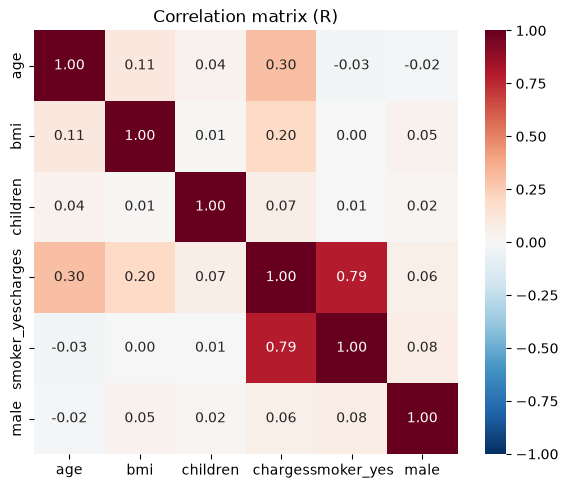

In [9]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix (R)')
plt.show()

**What the correlations say**
- **Smoking vs charges: R = 0.79**, by far the strongest relationship in the data.
- **Age vs charges: R = 0.30** and **BMI vs charges: R = 0.20**: moderate and weak positive correlations.
- Children, sex and every pair of *predictors* are close to 0 (|R| < 0.11), so no two input variables are redundant.

## 3.2 Pair plot

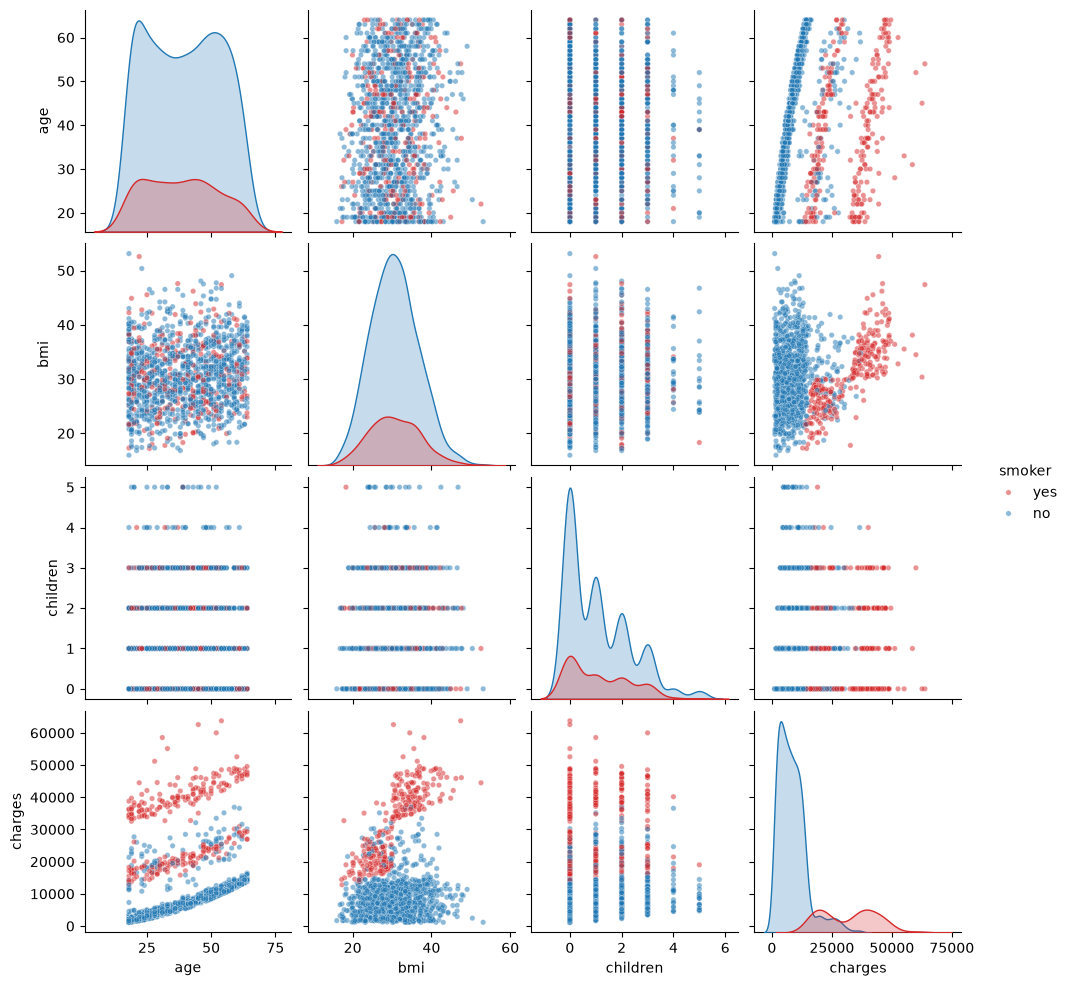

In [10]:
sns.pairplot(ins, vars=['age', 'bmi', 'children', 'charges'], hue='smoker',
             plot_kws={'alpha': 0.5, 's': 15}, palette={'no': '#1f77b4', 'yes': '#d62728'})
plt.show()

Colouring by `smoker` shows how much of the structure smoking explains: in every panel with `charges`, the red (smoker) points sit far above the blue ones.

## 3.3 Scatter plots for the largest correlations

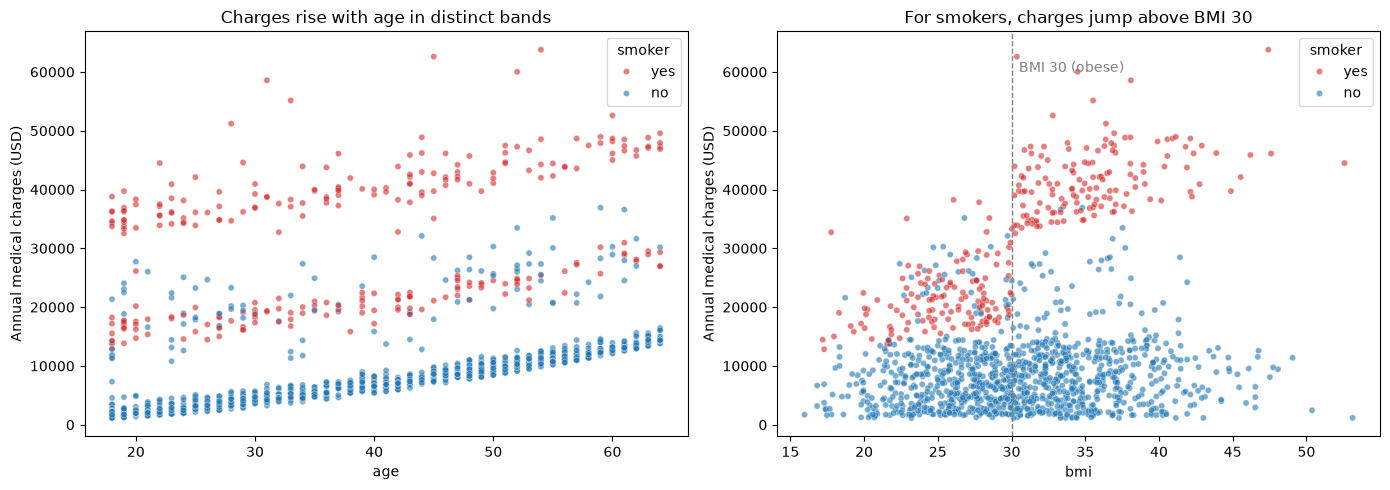

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pal = {'no': '#1f77b4', 'yes': '#d62728'}

sns.scatterplot(data=ins, x='age', y='charges', hue='smoker', palette=pal, alpha=0.6, s=20, ax=axes[0])
axes[0].set_title('Charges rise with age in distinct bands')

sns.scatterplot(data=ins, x='bmi', y='charges', hue='smoker', palette=pal, alpha=0.6, s=20, ax=axes[1])
axes[1].axvline(30, color='grey', linestyle='--', linewidth=1)
axes[1].text(30.5, 60000, 'BMI 30 (obese)', color='grey')
axes[1].set_title('For smokers, charges jump above BMI 30')

for ax in axes:
    ax.set_ylabel('Annual medical charges (USD)')
plt.tight_layout()
plt.show()

In [12]:
# Correlations within each smoking group
for grp, sub in ins.groupby('smoker'):
    print(f"smoker={grp:3}  n={len(sub):4}  "
          f"R(age, charges)={sub.age.corr(sub.charges):.2f}  "
          f"R(bmi, charges)={sub.bmi.corr(sub.charges):.2f}")

ins['obese'] = np.where(ins.bmi >= 30, 'BMI >= 30', 'BMI < 30')
ins.pivot_table(index='smoker', columns='obese', values='charges', aggfunc='mean').round(0)

smoker=no   n=1064  R(age, charges)=0.63  R(bmi, charges)=0.08
smoker=yes  n= 274  R(age, charges)=0.37  R(bmi, charges)=0.81


obese,BMI < 30,BMI >= 30
smoker,,
no,7977.0,8843.0
yes,21363.0,41558.0


Splitting by smoking status changes the picture:
- For **non-smokers**, age is the main driver (R = 0.63) and BMI barely matters (R = 0.08).
- For **smokers**, BMI is the main driver (R = 0.81). Smokers with BMI ≥ 30 average about \$41,600, around twice the \$21,400 for smokers under 30.

The overall BMI correlation (0.20) hides this, because it mixes two very different groups.

## 3.4 Line and area graphs
This dataset has **no date or time column**, so we can't plot a trend over calendar time. Age is the closest ordered variable, so these plots show how average charges change across ages.

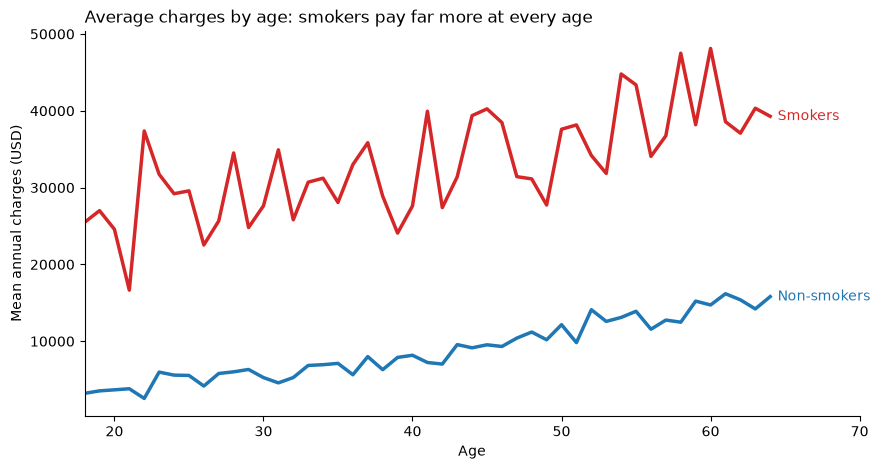

Smoker minus non-smoker gap by age: min $12,837, median $23,465, max $35,018


In [13]:
by_age = ins.groupby(['age', 'smoker']).charges.mean().unstack()

ax = by_age.plot(figsize=(10, 5), color=['#1f77b4', '#d62728'], linewidth=2.5, legend=False)
ax.text(64.5, by_age['no'].iloc[-1],  'Non-smokers', color='#1f77b4', va='center')
ax.text(64.5, by_age['yes'].iloc[-1], 'Smokers',     color='#d62728', va='center')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.set_title('Average charges by age: smokers pay far more at every age', loc='left')
ax.set_xlabel('Age')
ax.set_ylabel('Mean annual charges (USD)')
ax.set_xlim(18, 70)
plt.show()

gap = by_age['yes'] - by_age['no']
print(f"Smoker minus non-smoker gap by age: min ${gap.min():,.0f}, median ${gap.median():,.0f}, max ${gap.max():,.0f}")

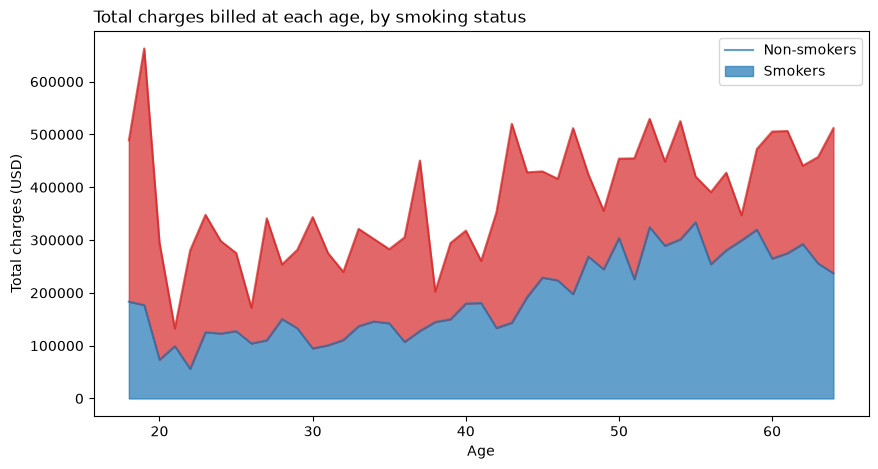

In [14]:
# Area plot: total charges billed at each age, split by smoking status
total_by_age = ins.groupby(['age', 'smoker']).charges.sum().unstack()
ax = total_by_age.plot.area(figsize=(10, 5), color=['#1f77b4', '#d62728'], alpha=0.7)
ax.set_title('Total charges billed at each age, by smoking status', loc='left')
ax.set_xlabel('Age')
ax.set_ylabel('Total charges (USD)')
ax.legend(['Non-smokers', 'Smokers'])
plt.show()

Unlike the nitrate/phosphate example, **stacking makes sense here**: total charges = non-smoker charges + smoker charges, so the top edge is a meaningful number. Smokers are only 20% of the people but account for about half (49.5%) of all charges. (The spike at age 18-19 is because the dataset has more people aged 18-19 than any other age, not because 18-year-olds cost more.)

In [15]:
print(ins.age.value_counts().sort_index().head(4))
print("\nSmokers' share of total charges:",
      round(ins.loc[ins.smoker == 'yes', 'charges'].sum() / ins.charges.sum() * 100, 1), "%")

age
18    69
19    68
20    29
21    28
Name: count, dtype: int64

Smokers' share of total charges: 49.5 %


## 3.5 Outliers

Charges outliers (1.5 x IQR rule): 139 | of which smokers: 136
BMI outliers: 9 | max BMI: 53.13


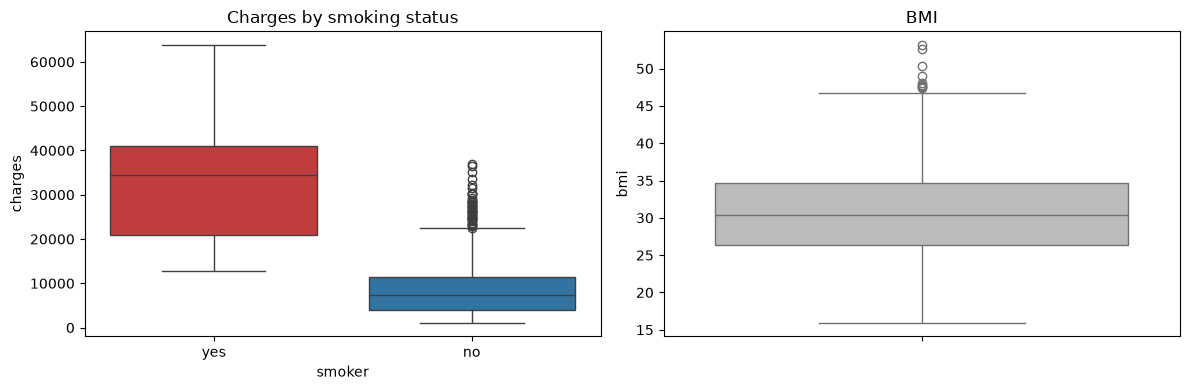

In [16]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 1.5 * (q3 - q1)

charge_out = iqr_outliers(ins.charges)
print("Charges outliers (1.5 x IQR rule):", charge_out.sum(),
      "| of which smokers:", (charge_out & (ins.smoker == 'yes')).sum())
print("BMI outliers:", iqr_outliers(ins.bmi).sum(), "| max BMI:", ins.bmi.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=ins, x='smoker', y='charges', ax=axes[0], palette=pal, hue='smoker', legend=False)
axes[0].set_title('Charges by smoking status')
sns.boxplot(data=ins, y='bmi', ax=axes[1], color='#bbbbbb')
axes[1].set_title('BMI')
plt.tight_layout()
plt.show()

In [17]:
# Check the duplicated row
ins[ins.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges,obese
195,19,male,30.59,0,no,northwest,1639.5631,BMI >= 30
581,19,male,30.59,0,no,northwest,1639.5631,BMI >= 30


## 3.6 Possible confounders: the regional difference

In [18]:
ins.groupby('region').agg(mean_charges=('charges', 'mean'),
                          mean_bmi=('bmi', 'mean'),
                          smoker_rate=('smoker', lambda s: (s == 'yes').mean())).round(2)

,mean_charges,mean_bmi,smoker_rate
region,,,
northeast,13406.38,29.17,0.21
northwest,12417.58,29.20,0.18
southeast,14735.41,33.36,0.25
southwest,12346.94,30.60,0.18


## 3.7 Conclusions

**Are the data what I expected? Are they usable?**
Yes. The data are clean: 1,338 rows, no missing values and only one duplicate row (two identical 19-year-old men in the northwest, which could be a real coincidence or a data-entry repeat; dropping it changes nothing). The relationships make medical sense: smoking, age and obesity all raise costs. The dataset is usable for the project. Its main limitation is that it's small and has few variables (no diagnoses, no dates).

**Outliers**
- 139 people have charges above the 1.5 × IQR cutoff (about \$34,500), and 136 of them are smokers. These aren't errors; they're the smoker group. Charges are strongly right-skewed (mean \$13,270 vs median \$9,382).
- 9 people have BMI outliers, up to 53.1. That's extreme but physically possible.
- In the age vs charges scatter plot, a band of non-smokers sits well above the main non-smoker line. Nothing in the dataset explains them (see confounders).

**Highly correlated / redundant variables**
None. The largest correlation between two *predictors* is age vs BMI at R = 0.11, so each variable carries its own information. The only strong correlation (smoker vs charges, R = 0.79) is between a predictor and the target, which makes smoking the most useful predictor.

**Trends over time / drift**
There's no date column, so drift over time can't be checked. The data look like a single snapshot. Comparisons with other years' costs would need adjusting for medical inflation. Across age (the substitute ordered axis), charges rise steadily and roughly linearly for both groups.

**Confounding variables**
- **Region:** the southeast has the highest average charges (\$14,735 vs about \$12,300-13,400 elsewhere), but it also has the highest average BMI (33.4) and the highest smoker rate (25%). The regional difference is likely explained by BMI and smoking, not location.
- **Sex:** men average \$13,957 vs \$12,570 for women, but more men smoke (23.5% vs 17.4%), so smoking may explain the gap.
- **Not in the dataset:** chronic conditions, diagnoses, hospital stays, insurance plan type and income are probably behind the unexplained band of high-cost non-smokers, and could influence the BMI and age relationships too.

# 4. Storytelling With Data plot (Chapter 3, second half)
Reproducing the chapter's step-by-step **decluttering** of the "Ticket volume over time" chart: each panel removes one more piece of clutter. Data values are approximate; the goal is the look and feel.

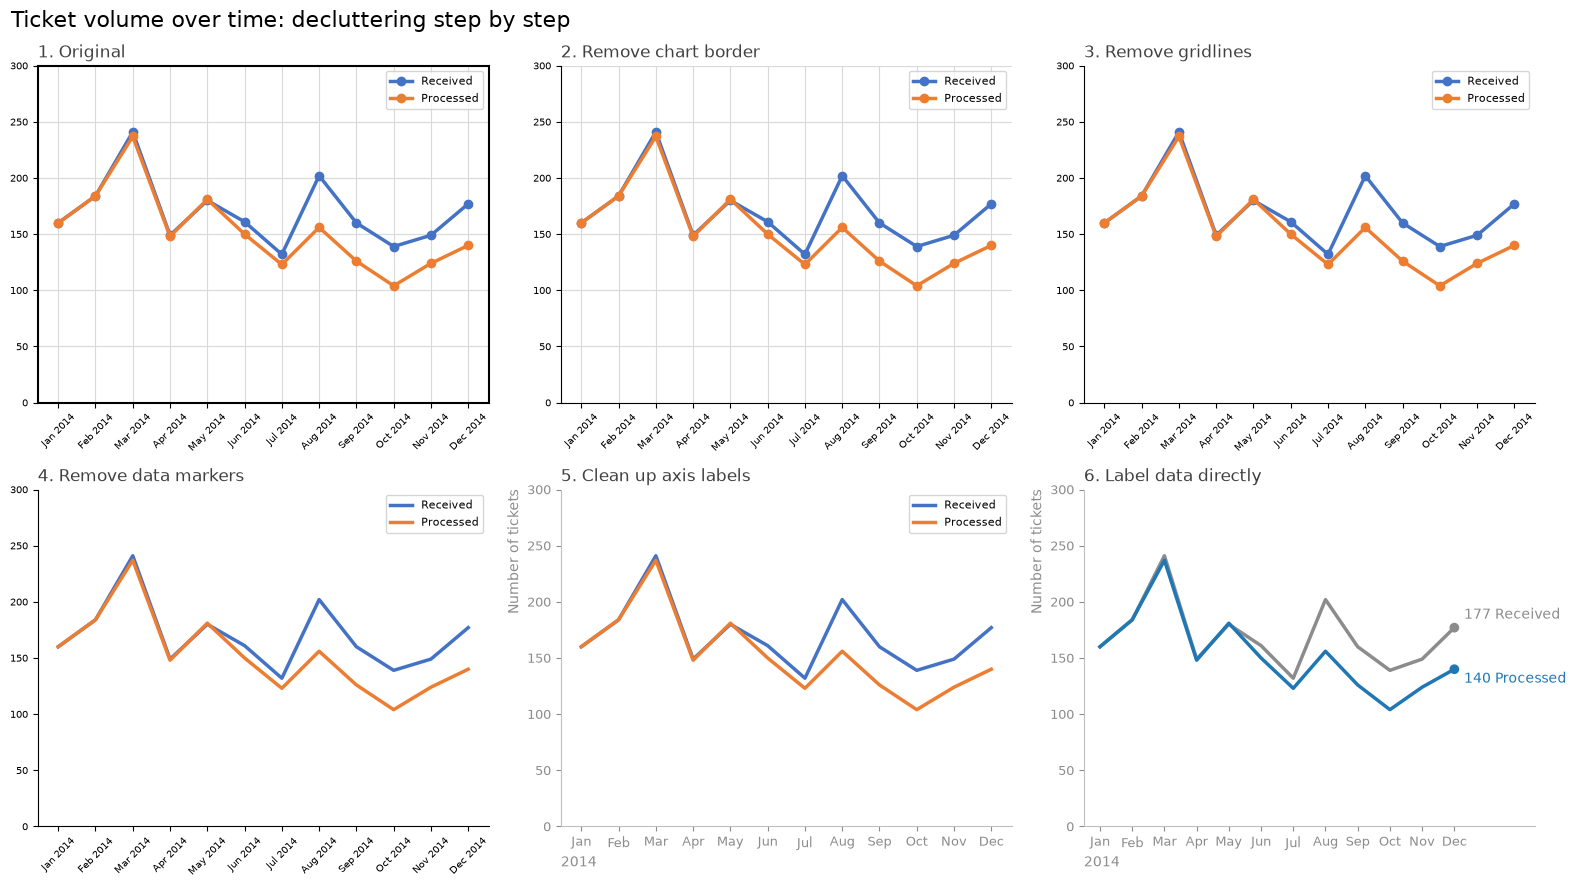

In [19]:
months_lbl = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
received  = [160,184,241,149,180,161,132,202,160,139,149,177]
processed = [160,184,237,148,181,150,123,156,126,104,124,140]
GREY, BLUE, LIGHT = '#8c8c8c', '#1f77b4', '#bfbfbf'

steps = ['1. Original', '2. Remove chart border', '3. Remove gridlines',
         '4. Remove data markers', '5. Clean up axis labels', '6. Label data directly']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, (ax, title) in enumerate(zip(axes.flat, steps)):
    step = i + 1
    marker = 'o' if step < 4 else None
    c_rec, c_proc = ('#4472c4', '#ed7d31') if step < 6 else (GREY, BLUE)
    ax.plot(months_lbl, received,  marker=marker, color=c_rec,  linewidth=2.5, label='Received')
    ax.plot(months_lbl, processed, marker=marker, color=c_proc, linewidth=2.5, label='Processed')
    ax.set_ylim(0, 300)

    # Step 1: boxed chart with gridlines and a legend
    if step < 3:
        ax.grid(True, color='#d9d9d9')
    if step == 1:
        for sp in ax.spines.values():
            sp.set_linewidth(1.5)
    else:
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
    if step >= 5:
        for side in ['left', 'bottom']:
            ax.spines[side].set_color(LIGHT)
        ax.tick_params(colors=GREY, labelsize=9)
        ax.set_ylabel('Number of tickets', color=GREY, loc='top')
        ax.set_xlabel('2014', color=GREY, loc='left')
    else:
        ax.tick_params(labelsize=7)
        plt.setp(ax.get_xticklabels(), rotation=45)
        ax.set_xticks(range(12))
        ax.set_xticklabels([f'{m} 2014' for m in months_lbl])

    if step < 6:
        ax.legend(loc='upper right', fontsize=8)
    else:
        ax.scatter([11, 11], [received[-1], processed[-1]], color=[GREY, BLUE], zorder=3)
        ax.set_xlim(-0.5, 13.5)
        ax.text(11.3, received[-1] + 8,  f'{received[-1]} Received',  color=GREY, fontsize=10)
        ax.text(11.3, processed[-1] - 12, f'{processed[-1]} Processed', color=BLUE, fontsize=10)

    ax.set_title(title, loc='left', fontsize=12, color='#404040')

plt.suptitle('Ticket volume over time: decluttering step by step', fontsize=16, x=0.01, ha='left')
plt.tight_layout()
plt.show()

Each step removes something that takes up the reader's attention without adding information:
1. **Original:** a heavy border, gridlines, data markers, rotated "Month Year" labels and a legend.
2. **Remove the chart border:** white space already separates the chart from the page.
3. **Remove the gridlines:** they compete with the data for attention.
4. **Remove the data markers:** the line shows the trend; markers add clutter.
5. **Clean up the axis labels:** show the year once instead of repeating it, push the axes into the background with grey, and add axis titles.
6. **Label the data directly:** names next to the lines replace the legend, and grey vs blue focuses attention on the processed tickets.